# XAI with Python

In this tutorial, we will see two scenarios of application of XAI using Python.

1. SHAP with a simple tabular model (Random Forest for regression) using the shap library.
2. Grad-CAM and Finer-CAM on a pretrained ResNet18 using pytorch-gradcam.

We will additionally see two variants over the previous examples:

1. SHAP with the GradientExplainer variant on the ResNet18 (base SHAP is often unfeasible on Neural Networks because of runtime)
2. IntegratedGradients

In [1]:
#!pip install -q shap captum torchvision matplotlib scikit-learn grad-cam

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
import shap

import torch
import torchvision.transforms as transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import requests
from io import BytesIO

from captum.attr import IntegratedGradients, LayerGradCam
from captum.attr import visualization as viz

from pytorch_grad_cam import GradCAM, FinerCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget, FinerWeightedTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

/home/vlitoux/Projects/XAI_repo/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
weights = ResNet18_Weights.DEFAULT
model_resnet = resnet18(weights=weights)
model_resnet.eval()

# Download a sample image (a dog)
url = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
response = requests.get(url)
img = Image.open(BytesIO(response.content))

# Automatically obtain the correct transforms from the weights configuration
transform = weights.transforms()

input_tensor = transform(img).unsqueeze(0)  # Shape: [1, 3, 224, 224]

# Predict target class
output = model_resnet(input_tensor)
pred_idx = torch.argmax(output).item()

# Retrieve the class name list from the weight metadata
categories = weights.meta["categories"]
class_name = categories[pred_idx]

print(f"Predicted Class Index: {pred_idx}")
print(f"Predicted Class Name: {class_name}")

Predicted Class Index: 258
Predicted Class Name: Samoyed


## Part 1: SHAP on California Housing Tabular Model

In [3]:
# Load data
california = fetch_california_housing(as_frame=True)
X = california.data
y = california.target

# Train a simple Random Forest
model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X, y)

# Initialize and execute SHAP explainer
explainer = shap.Explainer(model, X)
shap_values = explainer(X.iloc[:100])
shap_values

Background dataset has 20640 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=20640 when initializing the masker.


.values =
array([[ 2.17344302e+00,  1.66833621e-01,  1.07060871e-01,
        -2.56357363e-02, -3.27982010e-02,  8.71538605e-02,
        -2.98366994e-01,  3.28351795e-01],
       [ 1.73911155e+00, -6.07069717e-02,  3.87690049e-02,
        -1.05619500e-01,  4.17474002e-02,  2.39988686e-01,
        -2.67820297e-01,  3.05652866e-01],
       [ 1.60097701e+00,  1.11579136e-01,  1.45400793e-01,
         2.36654157e-03, -2.96579047e-02,  8.01425043e-03,
        -4.14370018e-01,  2.97611668e-01],
       [ 9.72683682e-01,  1.69836307e-01,  4.63076056e-03,
         9.47223026e-03, -5.87727618e-02,  2.23953862e-01,
        -2.48959192e-01,  4.42956642e-01],
       [ 1.22637099e-02,  1.16227530e-01,  6.98253172e-02,
         3.51291663e-02, -2.63824999e-02,  4.26673085e-01,
        -2.84064831e-01,  4.42369825e-01],
       [ 1.03901068e-01,  1.23036094e-01, -6.09079375e-02,
         1.48886033e-02, -1.15180907e-01,  4.88083463e-01,
        -2.92615964e-01,  3.66096909e-01],
       [-5.93948661e-02,

In [4]:
california.target

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [5]:
shap_values.base_values

array([1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484865,
       1.98484865, 1.98484865, 1.98484865, 1.98484865, 1.98484

In [6]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [7]:
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


### Plot 1.1 - Beeswarm global plot

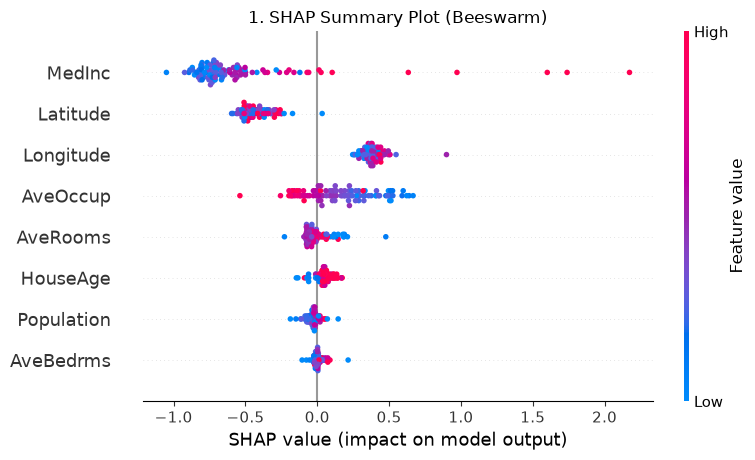

In [8]:

# 1. Plot SHAP summary (Beeswarm)
plt.figure(figsize=(10, 5))
shap.plots.beeswarm(shap_values, show=False)
plt.title("1. SHAP Summary Plot (Beeswarm)")
plt.tight_layout()
plt.show()


### Plot - 1.2 SHAP Waterfall plot (local)

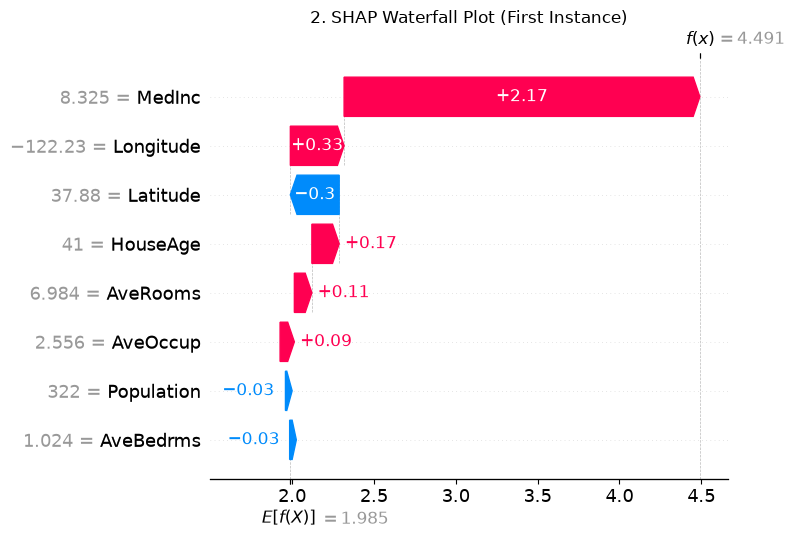

In [9]:

# 2. Plot SHAP Waterfall plot for the first prediction
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[0], show=False)
plt.title("2. SHAP Waterfall Plot (First Instance)")
plt.tight_layout()
plt.show()


### Plot 1.3 - SHAP Force plot (alternative to waterfall)

<Figure size 1200x400 with 0 Axes>

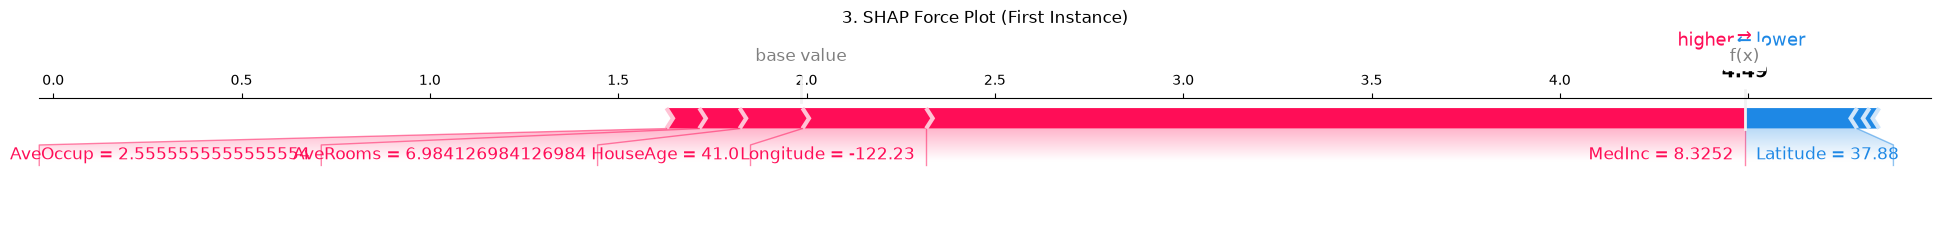

In [10]:

# 3. Plot SHAP Force plot for the first prediction
# Note: shap.initjs() is required for interactive force plots in notebooks,
# but we can render it as a matplotlib plot using matplotlib=True.
plt.figure(figsize=(12, 4))
shap.plots.force(shap_values.base_values[0], shap_values.values[0], X.iloc[0], matplotlib=True, show=False)
plt.title("3. SHAP Force Plot (First Instance)", y=1.5)
plt.tight_layout()
plt.show()

### Plot 1.4 - SHAP scatter plot on one single feature (global)

In [11]:
type(shap_values)

shap._explanation.Explanation

In [12]:
shap_values[:, "MedInc"].shape

(100,)

In [13]:
shap_values

.values =
array([[ 2.17344302e+00,  1.66833621e-01,  1.07060871e-01,
        -2.56357363e-02, -3.27982010e-02,  8.71538605e-02,
        -2.98366994e-01,  3.28351795e-01],
       [ 1.73911155e+00, -6.07069717e-02,  3.87690049e-02,
        -1.05619500e-01,  4.17474002e-02,  2.39988686e-01,
        -2.67820297e-01,  3.05652866e-01],
       [ 1.60097701e+00,  1.11579136e-01,  1.45400793e-01,
         2.36654157e-03, -2.96579047e-02,  8.01425043e-03,
        -4.14370018e-01,  2.97611668e-01],
       [ 9.72683682e-01,  1.69836307e-01,  4.63076056e-03,
         9.47223026e-03, -5.87727618e-02,  2.23953862e-01,
        -2.48959192e-01,  4.42956642e-01],
       [ 1.22637099e-02,  1.16227530e-01,  6.98253172e-02,
         3.51291663e-02, -2.63824999e-02,  4.26673085e-01,
        -2.84064831e-01,  4.42369825e-01],
       [ 1.03901068e-01,  1.23036094e-01, -6.09079375e-02,
         1.48886033e-02, -1.15180907e-01,  4.88083463e-01,
        -2.92615964e-01,  3.66096909e-01],
       [-5.93948661e-02,

<Figure size 1000x500 with 0 Axes>

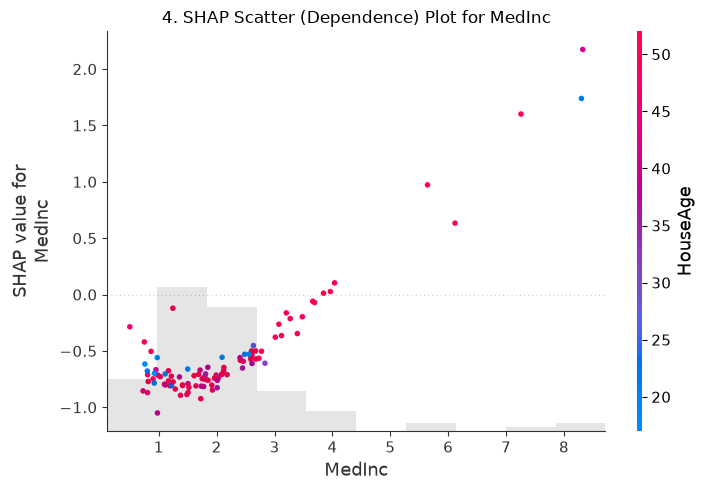

In [14]:

# 4. Plot SHAP Scatter plot for the most important feature (usually MedInc)
plt.figure(figsize=(10, 5))
shap.plots.scatter(shap_values[:, "MedInc"], color=shap_values, show=False)
plt.title("4. SHAP Scatter (Dependence) Plot for MedInc")
plt.tight_layout()
plt.show()


## Part 2 - GradCAM and variants using captum

First, we download the pretrained ResNet18 model, we get an image of a Samoyed dog, preprocess it via the data contained in the weights structure, and get the prediction.

In [15]:
weights = ResNet18_Weights.DEFAULT
model_resnet = resnet18(weights=weights)
model_resnet.eval()

# Download a sample image (a dog)
url = "https://www.cdc.gov/healthy-pets/media/images/2024/04/Cat-on-couch.jpg"
response = requests.get(url)
img = Image.open(BytesIO(response.content))

# Automatically obtain the correct transforms from the weights configuration
transform = weights.transforms()

input_tensor = transform(img).unsqueeze(0)  # Shape: [1, 3, 224, 224]

# Predict target class
output = model_resnet(input_tensor)
pred_idx = torch.argmax(output).item()

# Retrieve the class name list from the weight metadata
categories = weights.meta["categories"]
class_name = categories[pred_idx]

print(f"Predicted Class Index: {pred_idx}")
print(f"Predicted Class Name: {class_name}")

Predicted Class Index: 281
Predicted Class Name: tabby


### Grad-CAM via pytorch-grad-cam



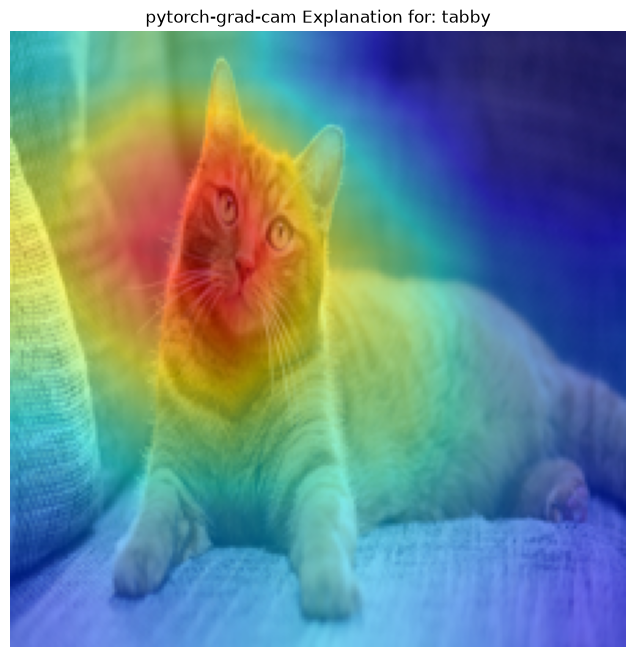

In [16]:

# Define the target layer for ResNet18 (typically the last convolutional layer before pooling)
target_layers = [model_resnet.layer4[-1]]

# Instantiate the GradCAM explainer from the grad-cam package
cam = GradCAM(model=model_resnet, target_layers=target_layers)

# We want to explain the top predicted class
targets = [ClassifierOutputTarget(pred_idx)]

# Generate the raw grayscale CAM mask
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)

# Take the first image in the batch
grayscale_cam = grayscale_cam[0, :]

# Prepare input image normalized to [0, 1] range
rgb_img = np.array(img.resize((224, 224))) / 255.0

# Overlay the heatmap on the original image
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# Plot the results
plt.figure(figsize=(8, 8))
plt.imshow(visualization)
plt.title(f"pytorch-grad-cam Explanation for: {class_name}")
plt.axis('off')
plt.show()

## Grad-CAM via captum

On captum, Grad-CAM needs to be implemented starting from LayerGradCAM.

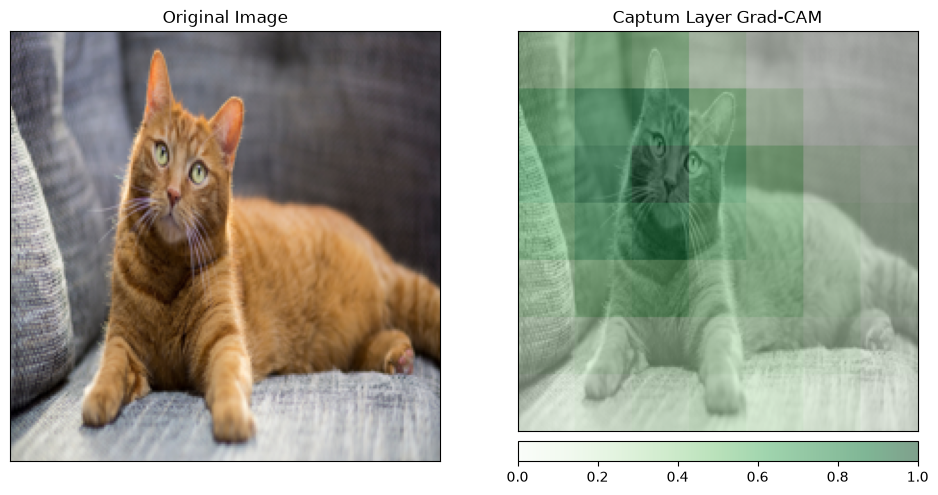

In [17]:

# Captum Grad-CAM Setup
# We target the last convolutional layer of ResNet18: model_resnet.layer4[-1]
lgc = LayerGradCam(model_resnet, model_resnet.layer4[-1])

# Attribute
attribution_gradcam = lgc.attribute(input_tensor, target=pred_idx)

# Format attributions for visualization
# We upsample the heatmap to match the input size [224, 224]
upsampled_attr = LayerGradCam.interpolate(attribution_gradcam, (224, 224))
attr_numpy = upsampled_attr.squeeze().cpu().detach().numpy()
attr_numpy = np.transpose(attr_numpy, (0, 1)) # Handle dimensions

# Prepare input image numpy for visualization
original_img_np = np.array(img.resize((224, 224))) / 255.0

# Visualization using Captum's helper
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# Fix: Pass the actual attribution array (instead of a zero-array) to avoid scale factor = 0.
# Setting method="original_image" ensures Captum only draws the background image without overlay.
_ = viz.visualize_image_attr(
    attr_numpy[:, :, np.newaxis],
    original_img_np,
    method="original_image",
    title="Original Image",
    plt_fig_axis=(fig, axs[0]),
    use_pyplot=False
)

_ = viz.visualize_image_attr(
    attr_numpy[:, :, np.newaxis],
    original_img_np,
    method="blended_heat_map",
    sign="positive",
    show_colorbar=True,
    title="Captum Layer Grad-CAM",
    plt_fig_axis=(fig, axs[1]),
    use_pyplot=False
)

plt.tight_layout()
plt.show()


Take a second of your time to reason on the differences in the visualizations from Grad-CAM and LayerGradCam. Why are the two plots so different, despite actually showing the same quantity?

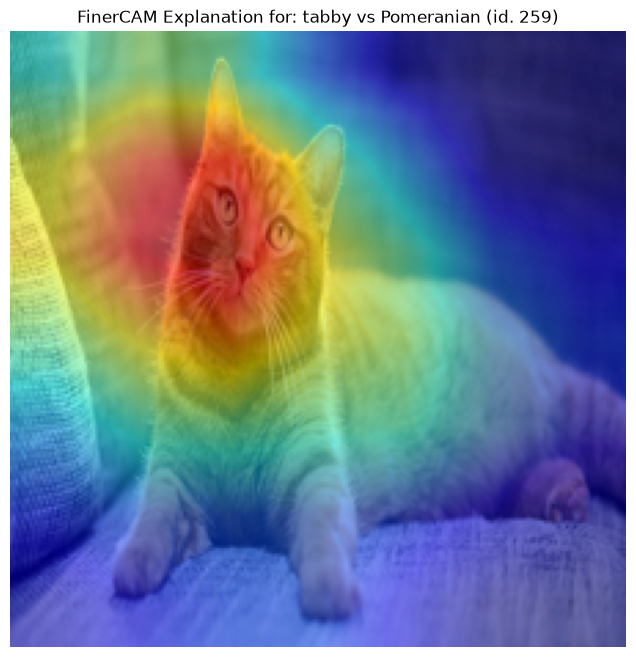

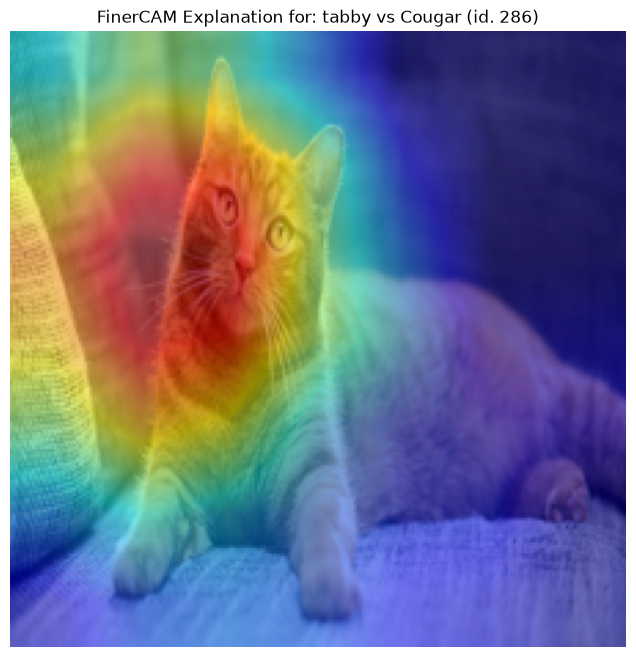

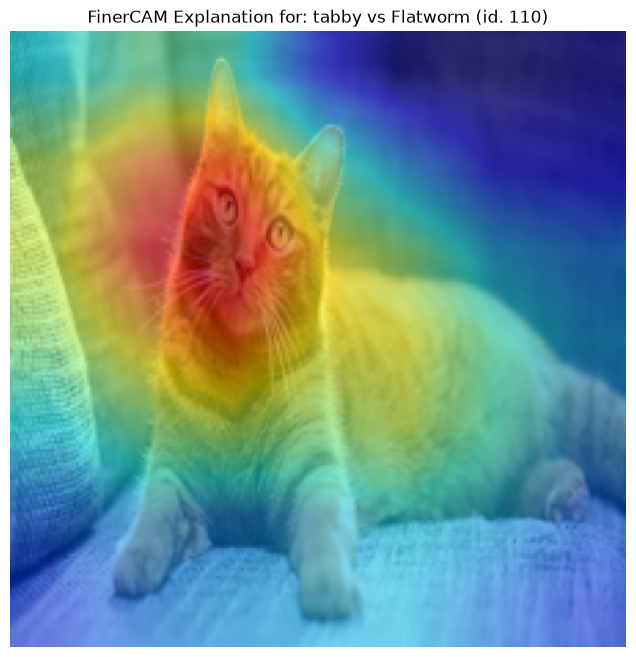

In [18]:
def finer_map(model, main_category, reference_category, alpha=1.0):
    targets = [FinerWeightedTarget(main_category=main_category,
                                   comparison_categories=[reference_category],
                                   alpha=alpha)]
    with FinerCAM(model=model, target_layers=target_layers) as cam:
        out = cam(input_tensor=input_tensor, targets=targets)
    # depending on the version, FinerCAM may return the map alone
    # or a tuple (cam_map, outputs, main_categories, references)
    out = out[0] if isinstance(out, tuple) else out
    return out[0]


for reference_class, desc in {259: "Pomeranian", 286: "Cougar", 110: "Flatworm"}.items():

  grayscale_cam = finer_map(model_resnet, pred_idx, reference_class)

  # Overlay the heatmap on the original image
  visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

  # Plot the results
  plt.figure(figsize=(8, 8))
  plt.imshow(visualization)
  plt.title(f"FinerCAM Explanation for: {class_name} vs {desc} (id. {reference_class})")
  plt.axis('off')
  plt.show()


Running Integrated Gradients...


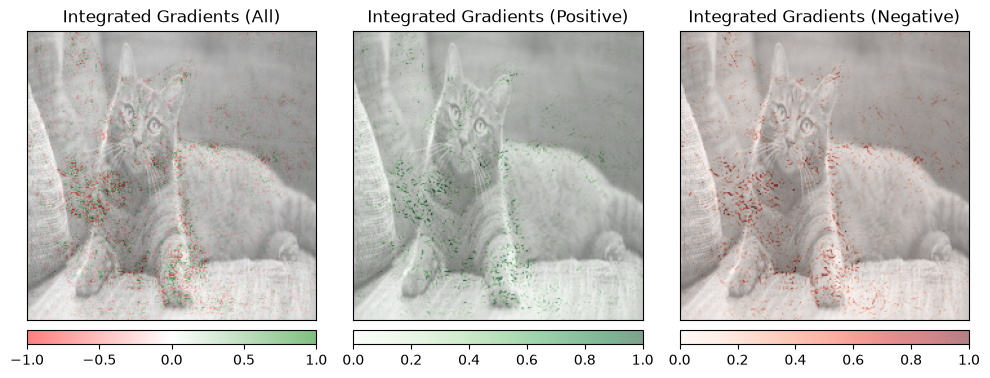

In [19]:

# Alternative: Captum Integrated Gradients
print("\nRunning Integrated Gradients...")
ig = IntegratedGradients(model_resnet)
attr_ig, delta = ig.attribute(input_tensor, target=pred_idx, return_convergence_delta=True)

attr_ig_np = np.transpose(attr_ig.squeeze().cpu().detach().numpy(), (1, 2, 0))

fig, axs = plt.subplots(1, 3, figsize=(10, 5))

_ = viz.visualize_image_attr(
    attr_ig_np,
    original_img_np,
    method="blended_heat_map",
    sign="all",
    show_colorbar=True,
    title="Integrated Gradients (All)",
    plt_fig_axis=(fig, axs[0]),
    use_pyplot=False
)

_ = viz.visualize_image_attr(
    attr_ig_np,
    original_img_np,
    method="blended_heat_map",
    sign="positive",
    show_colorbar=True,
    title="Integrated Gradients (Positive)",
    plt_fig_axis=(fig, axs[1]),
    use_pyplot=False
)

_ = viz.visualize_image_attr(
    attr_ig_np,
    original_img_np,
    method="blended_heat_map",
    sign="negative",
    show_colorbar=True,
    title="Integrated Gradients (Negative)",
    plt_fig_axis=(fig, axs[2]),
    use_pyplot=False
)

plt.tight_layout()
plt.show()

### Explaining Images using Patch-based (Superpixel) SHAP

Instead of calculating SHAP values for every single pixel, we can group pixels into "superpixels" (patches) using an image masker. This makes the explanation much more readable and computationally efficient.

PartitionExplainer explainer: 2it [00:21, 21.10s/it]               


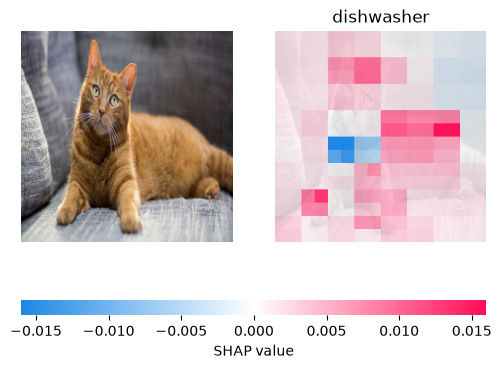

In [20]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Define a prediction function that takes numpy images, preprocesses them for PyTorch ResNet, and returns logits
def predict_fn(numpy_images):
    # numpy_images has shape (batch, height, width, channels)
    # Convert to PyTorch tensor format (batch, channels, height, width)
    tensor = torch.tensor(numpy_images, dtype=torch.float32).permute(0, 3, 1, 2)
    # Move to GPU if available
    if torch.cuda.is_available():
        tensor = tensor.cuda()
        global model_resnet
        model_resnet = model_resnet.cuda()

    with torch.no_grad():
        logits = model_resnet(tensor)
    return logits.cpu().numpy()

# Prepare our input image as a NumPy array [224, 224, 3] in the [0, 255] range
rgb_img_255 = np.array(img.resize((224, 224)))

# 2. Create an Image Masker using Superpixels (slic segmentation)
# This segments the image into coherent patches
masker = shap.maskers.Image("inpaint_telea", shape=(224, 224, 3))

# 3. Initialize PartitionExplainer
explainer_partition = shap.Explainer(predict_fn, masker, output_names=categories)

# 4. Explain the target image class (tabby cat)
# We search for the top 1 explanation class to keep it fast
shap_values_patches = explainer_partition(
    np.expand_dims(rgb_img_255, axis=0),
    max_evals=500,
    batch_size=50,
    outputs=shap.Explanation.argsort.flip[:1]
)

# 5. Plot patch-based SHAP explanations
shap.image_plot(shap_values_patches)


### Saving multiple explanations

We will now be saving a batch of 100 explanations which we will be using tomorrow for evaluation purposes.

We will use Grad-CAM on the first 100 units from the ImageNette test set.

We save
- the original image (since we downloaded it from the internet)
- the "grayscale_cam" explanation (a matrix defining the importance). Notice: **DON'T SAVE THE EXPLANATION OVERLAPPED ON THE IMAGE!** We will need the explanation separate from the image

In [21]:
import os
import torch
import torchvision
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import urllib.request
import tarfile

# Create output directories
os.makedirs("outputs/original", exist_ok=True)
os.makedirs("outputs/gradcam", exist_ok=True)

# Download Imagenette (a 10-class subset of ImageNet from Fast.ai)
url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
tar_path = "./imagenette2-320.tgz"
if not os.path.exists(tar_path):
    print("Downloading Imagenette (10-class ImageNet subset)...")
    urllib.request.urlretrieve(url, tar_path)
    with tarfile.open(tar_path, "r:gz") as tar_ref:
        tar_ref.extractall("./")

# Use the validation subset of Imagenette
test_dir = "./imagenette2-320/val"

# Gather paths to the first 100 images
image_paths = []
for root, _, files_list in os.walk(test_dir):
    for file in files_list:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, file))
    if len(image_paths) >= 100:
        break
image_paths = image_paths[:100]

# We use the official ResNet transforms for model inference
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()

# Instantiate GradCAM
target_layers = [model_resnet.layer4[-1]]
cam = GradCAM(model=model_resnet, target_layers=target_layers)

print("Processing the first 100 images from Imagenette...")
for i, img_path in enumerate(image_paths):
    # Get raw image
    pil_img = Image.open(img_path).convert("RGB")
    pil_img_resized = pil_img.resize((224, 224))

    # Save original image
    pil_img_resized.save(f"outputs/original/img_{i}.png")

    # Preprocess for model input
    input_tensor = preprocess(pil_img_resized).unsqueeze(0)
    if torch.cuda.is_available():
        input_tensor = input_tensor.cuda()
        model_resnet = model_resnet.cuda()

    # Get top predicted index
    with torch.no_grad():
        output = model_resnet(input_tensor)
        pred_idx = torch.argmax(output).item()

    # Generate Grad-CAM attribution
    targets = [ClassifierOutputTarget(pred_idx)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

    # Save the raw explanation attribution map as a numpy file
    np.save(f"outputs/gradcam/explanation_{i}.npy", grayscale_cam)

print("Done! Saved 100 original images to 'outputs/original' and raw explanations as .npy files to 'outputs/gradcam'.")

/tmp/ipykernel_3221486/3024928148.py:23: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar_ref.extractall("./")


Processing the first 100 images from Imagenette...
Done! Saved 100 original images to 'outputs/original' and raw explanations as .npy files to 'outputs/gradcam'.


In [22]:
import shutil
from google.colab import files

# Compress the outputs folder containing both original and gradcam subfolders
shutil.make_archive("gradcam_explanations", "zip", "outputs")

# Trigger the download of the zip file to your local computer
files.download("gradcam_explanations.zip")

ModuleNotFoundError: No module named 'google.colab'